# **1. 실습코드00**

ITK-SNAP으로 day15를 day0에 registration을 진행한 결과파일을 불러와서 같은 단면을 day0, day15에 대해 display하여 비교하기.

In [ ]:
!pip install nibabel

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import nibabel as nib

In [ ]:
h = nib.load('volume-covid19-A-0700_02.04.nii')
print(h.shape)

(512, 512, 70)


In [ ]:
print(h.header)

<class 'nibabel.nifti1.Nifti1Header'> object, endian='<'
sizeof_hdr      : 348
data_type       : b''
db_name         : b''
extents         : 0
session_error   : 0
regular         : b'r'
dim_info        : 0
dim             : [  3 512 512  70   1   1   1   1]
intent_p1       : 0.0
intent_p2       : 0.0
intent_p3       : 0.0
intent_code     : none
datatype        : int16
bitpix          : 16
slice_start     : 0
pixdim          : [1.   0.74 0.74 5.   0.   0.   0.   0.  ]
vox_offset      : 0.0
scl_slope       : nan
scl_inter       : nan
slice_end       : 0
slice_code      : unknown
xyzt_units      : 2
cal_max         : 0.0
cal_min         : 0.0
slice_duration  : 0.0
toffset         : 0.0
glmax           : 0
glmin           : 0
descrip         : b''
aux_file        : b''
qform_code      : scanner
sform_code      : unknown
quatern_b       : 0.0
quatern_c       : 0.0
quatern_d       : 1.0
qoffset_x       : 207.63699340820312
qoffset_y       : 189.08309936523438
qoffset_z       : -1019.5
srow_x

In [ ]:
ct_base = h.get_fdata()
print(ct_base.dtype, ct_base.shape)
print(np.min(ct_base),np.max(ct_base))

float64 (512, 512, 70)
-5363.0 30689.0


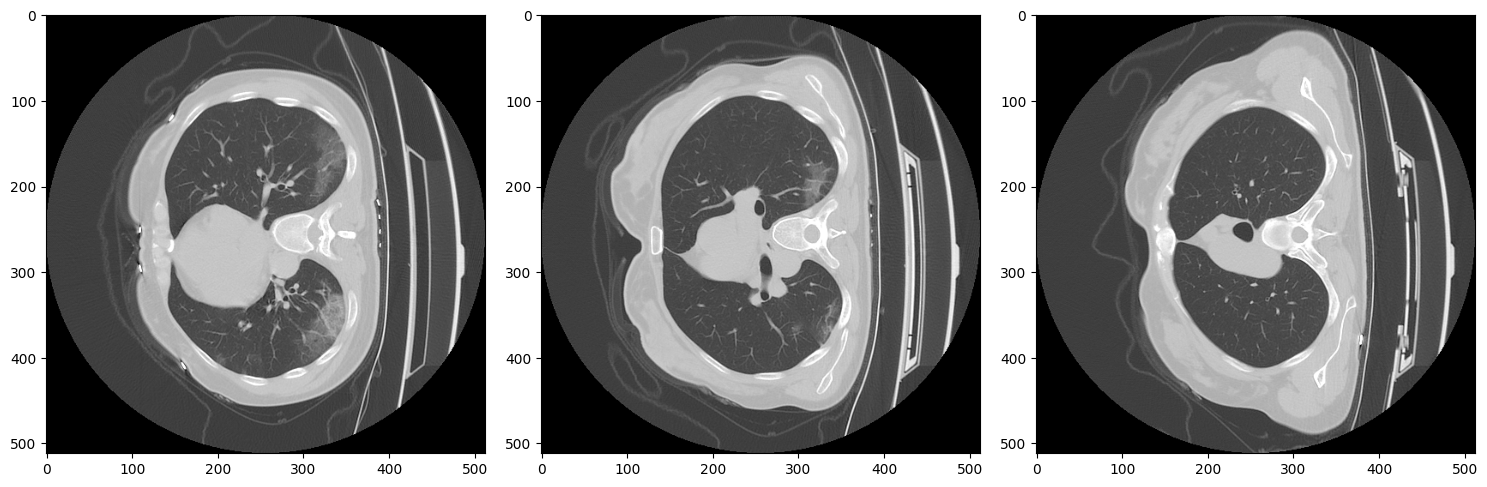

In [ ]:
plt.figure(figsize=(15,5))
plt.subplot(131)
plt.imshow(ct_base[:,:,30],vmin=-1500,vmax=500,cmap='gray')
plt.subplot(132)
plt.imshow(ct_base[:,:,40],vmin=-1500,vmax=500,cmap='gray')
plt.subplot(133)
plt.imshow(ct_base[:,:,50],vmin=-1500,vmax=500,cmap='gray')
plt.tight_layout()
plt.show()

In [ ]:
ct_FU = nib.load('volume-covid19-A-0700_02.19.nii').get_fdata()
ct_FU_reg = nib.load('0219registered.nii').get_fdata()

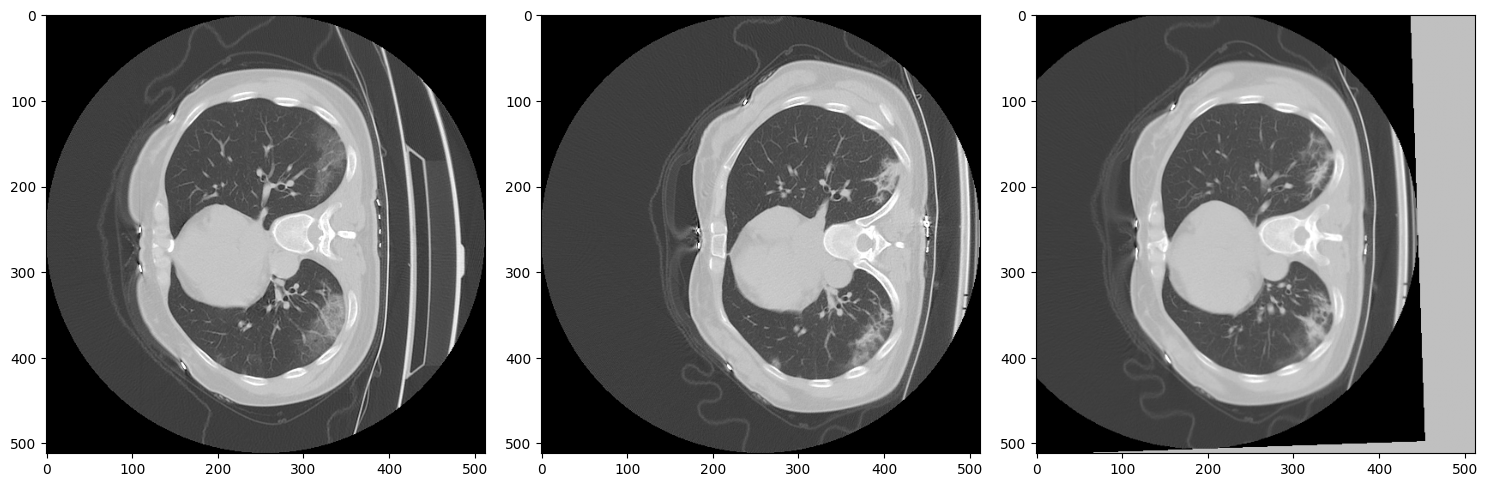

In [ ]:
plt.figure(figsize=(15,5))
plt.subplot(131)
plt.imshow(ct_base[:,:,30],vmin=-1500,vmax=500,cmap='gray')
plt.subplot(132)
plt.imshow(ct_FU[:,:,30],vmin=-1500,vmax=500,cmap='gray')
plt.subplot(133)
plt.imshow(ct_FU_reg[:,:,30],vmin=-1500,vmax=500,cmap='gray')
plt.tight_layout()
plt.show()

# 2. **실습코드01**

Exercise 1. local histogram equalization을 통해 숨겨진 패턴 확인하기

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os
imgpath = '/content/drive/MyDrive/DIP4E'
os.listdir(imgpath)

['implant.tif',
 'spine.tif',
 'aerialview-washedout.tif',
 'pollen-lowcontrast.tif',
 'hubble.tif',
 'contact-lens.tif',
 'moon-blurred.tif',
 'fingerprint-noisy.tif',
 'lincoln.tif',
 'chickenXray-thresholded.tif',
 'chickenXray.tif',
 'chickenfilet-with-bones.tif',
 'book-cover.tif',
 'aerial_view.tif',
 'rose512.tif',
 'rose1024.tif',
 'crowd.tif',
 'lenna-gray.tif',
 'kneeMRI.tif',
 'crabpulsar-gamma.tif',
 'crabpulsar-radio.tif',
 'crabpulsar-optical.tif',
 'crabpulsar-infrared.tif',
 'radar-tibet-mountains.tif',
 'chestXray2.tif',
 'OpticalMicroscope-taxol-anti-cancer-agent.tif',
 'OpticalMicroscope-nickel-oxide-film.tif',
 'OpticalMicroscope-surface-of-audio-CD.tif',
 'americas-at-night1.tif',
 'americas-at-night2.tif',
 'americas-at-night3.tif',
 'americas-at-night4.tif',
 'bottles-assembly-line.tif',
 'bubbles.tif',
 'cktboard-controller.tif',
 'pills.tif',
 'cereal.tif',
 'crabpulsar-xray.tif',
 'OpticalMicroscope-microporcessor-regular- texture.tif',
 'OpticalMicroscope-cho

In [4]:
f = plt.imread(imgpath+'/hidden-symbols.tif')
print(f.shape,f.dtype)

(256, 256) uint8


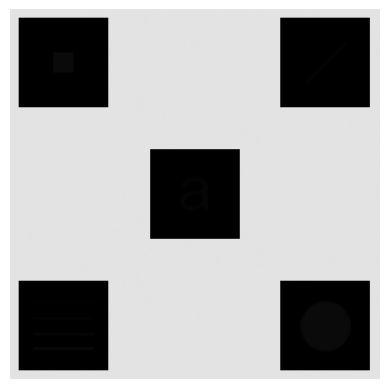

In [5]:
plt.imshow(f,vmin=0,vmax=255,cmap='gray')
plt.axis('off')
plt.show()

In [9]:
def histogram_equalization(image):
    histogram, bins = np.histogram(image.flatten(), bins=256, range=[0,256])
    cdf = histogram.cumsum()
    cdf_min = cdf.min()
    cdf_max = cdf.max()
    cdf_normalized = (cdf - cdf_min) * 255 / (cdf_max - cdf_min)
    cdf_normalized = cdf_normalized.astype(np.uint8)
    equalized_image = cdf_normalized[image]
    return equalized_image

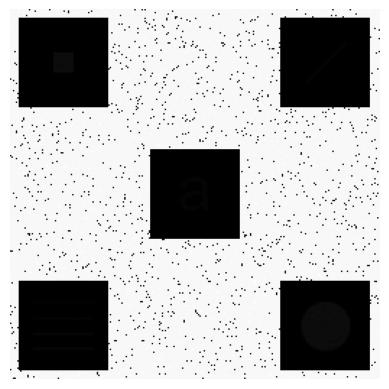

In [10]:
f_eq = histogram_equalization(f)
plt.imshow(f_eq,vmin=0,vmax=255,cmap='gray')
plt.axis('off')
plt.show()

/tmp/ipykernel_1331/3935879381.py:6: RuntimeWarning: invalid value encountered in divide
  cdf_normalized = (cdf - cdf_min) * 255 / (cdf_max - cdf_min)
/tmp/ipykernel_1331/3935879381.py:7: RuntimeWarning: invalid value encountered in cast
  cdf_normalized = cdf_normalized.astype(np.uint8)


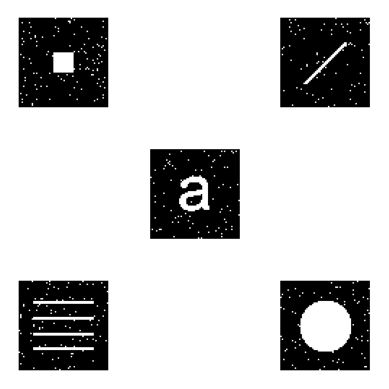

In [16]:
N = 1
f_eq_local = np.zeros_like(f)
for x in np.arange(0,256,N):
  for y in np.arange(0,256,N):
    f_eq_local[x:x+N,y:y+N] = histogram_equalization(f[x:x+N,y:y+N])

plt.imshow(f_eq_local,vmin=0,vmax=255,cmap='gray')
plt.axis('off')
plt.show()

# **3. 실습코드01**

Exercise 2. 본인의 사진을 grayscale image로 불러온 후, 서로 다른 kernel size에 대한 LPF결과 비교

In [17]:
import scipy.signal as signal
from skimage import io

In [18]:
f = io.imread('/content/IMG_0701.jpeg',as_gray=True)
print(f.shape,f.dtype)

(2956, 3941) float64


In [19]:
import time

computation time =  0.6528275012969971  sec


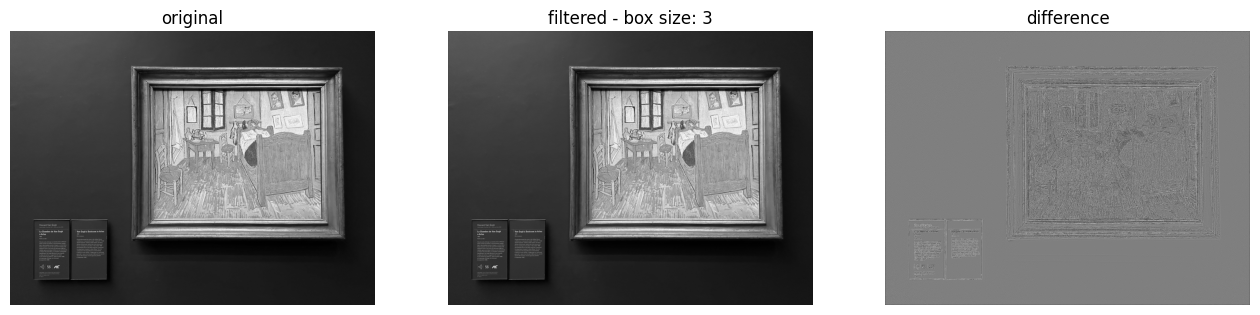

computation time =  3.2789480686187744  sec


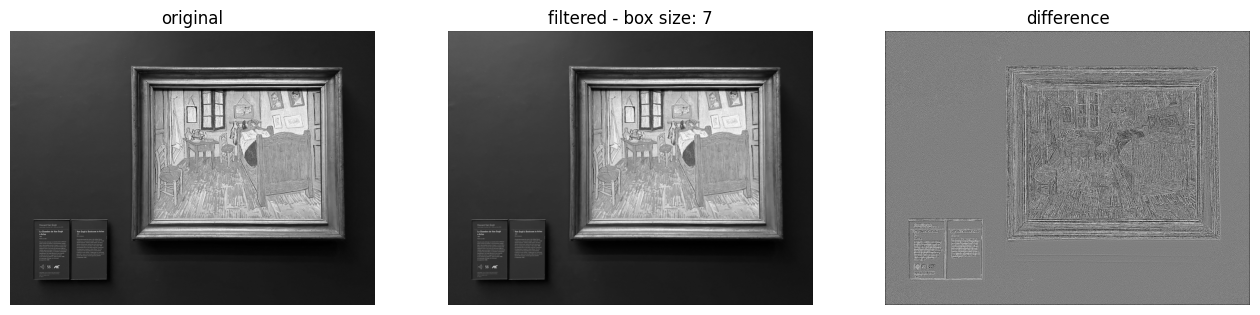

computation time =  8.151450872421265  sec


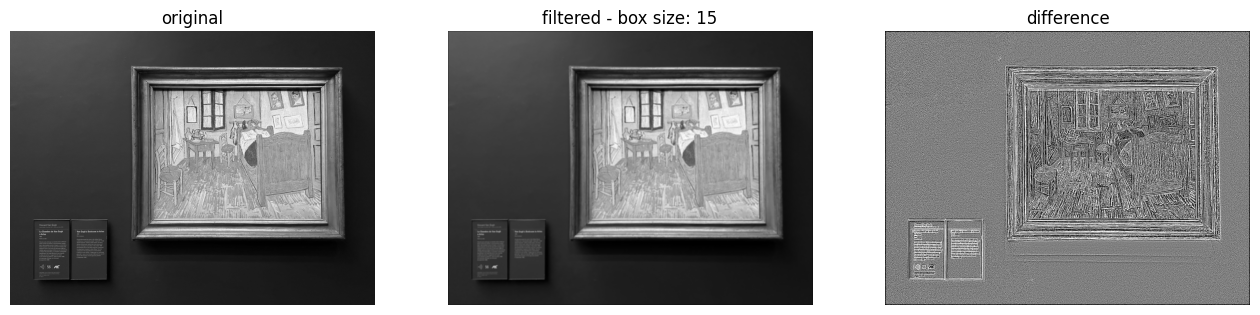

computation time =  27.50974202156067  sec


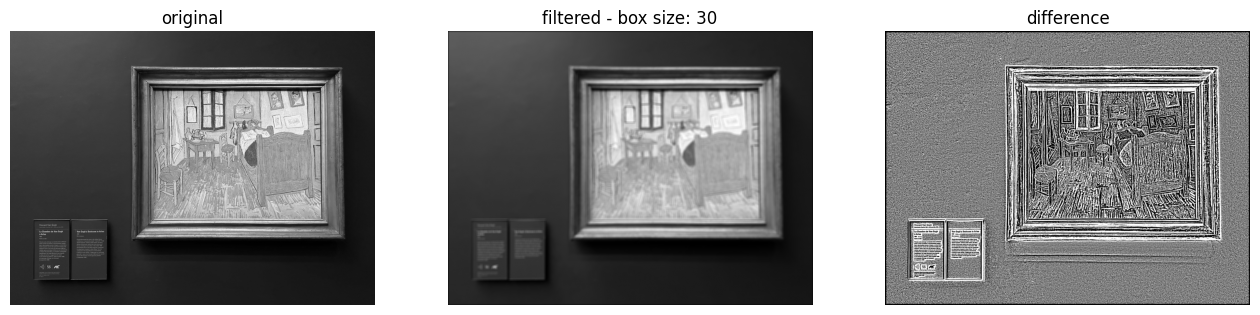

In [20]:
for N in np.array([3,7,15,30]):
  wb = np.ones((N,N))
  wb = wb/np.sum(wb)
  s0 = time.time()
  y_b = signal.convolve2d(f,wb,mode='same')
  compu_time=time.time() - s0
  print('computation time = ', compu_time,' sec')
  plt.figure(figsize=(16,9))
  plt.subplot(1,3,1)
  plt.imshow(f,cmap='gray')
  plt.axis('off')
  plt.title('original')
  plt.subplot(1,3,2)
  plt.imshow(y_b,cmap='gray')
  plt.axis('off')
  plt.title(f'filtered - box size: {N}')
  plt.subplot(1,3,3)
  plt.imshow(y_b-f,cmap='gray',vmin=-.01,vmax=.01)
  plt.axis('off')
  plt.title('difference')
  plt.show()

# **4. 실습코드01**

Exercise 3. Blurring이 발생한 사진을 가져와서 적당한 HPF결과를 활용하여 sharpening을 진행하기

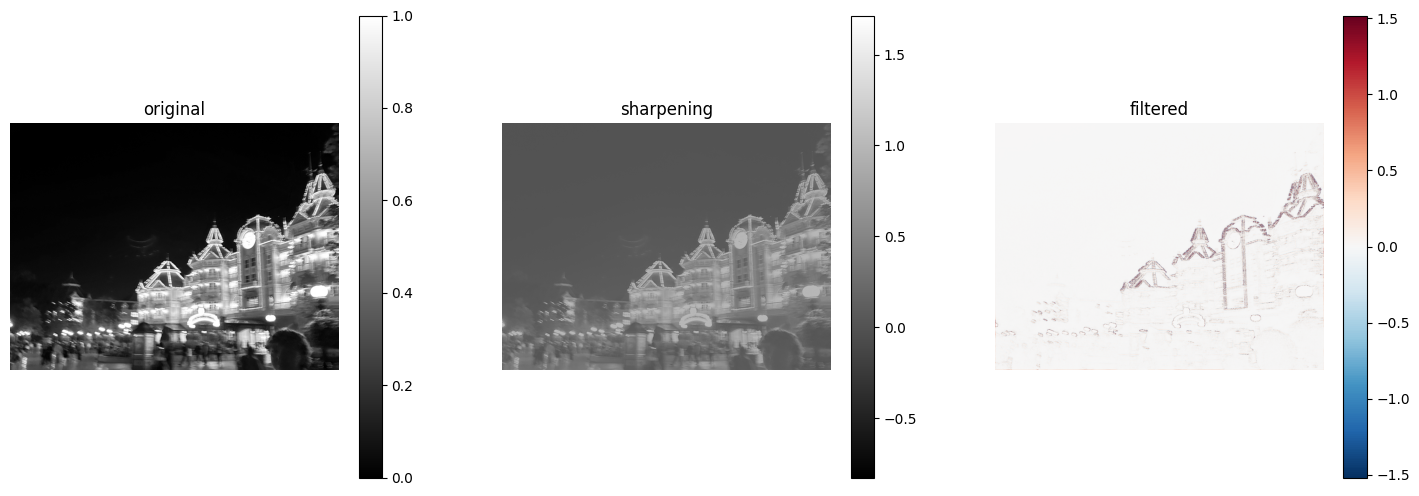

In [40]:
f = io.imread('/content/IMG_9716.jpeg',as_gray=True)[::2,::2]
w = np.array([[0,-1,0],[-1,4.,-1],[0,-1,0]])
y = signal.convolve2d(f,w,mode='same')
c = 0.3
g = f + c*(y)
plt.figure(figsize=(18,6))
plt.subplot(131)
plt.imshow(f,cmap='gray')
plt.colorbar()
plt.axis('off')
plt.title('original')
plt.subplot(132)
plt.imshow(g,cmap='gray')
plt.colorbar()
plt.axis('off')
plt.title('sharpening')
plt.subplot(133)
plt.imshow(y,cmap='RdBu_r',vmin=-0.5*np.max(np.abs(y)),vmax=0.5*np.max(np.abs(y)))
plt.colorbar()
plt.axis('off')
plt.title('filtered')
plt.show()